**Question:** Can an offense's play call (run vs. pass) be predicted from situational factors such as down, distance, field position, score differential, time remaining, timeouts, tempo (no-huddle), and offensive personnel? This is tested for the league as a whole and for one specific team, since play-calling tendencies vary significantly by coaching staff.

**Data Sources:** Imported nflreadpy and two datasets within it for the 2025 season. load_pbp() provides down/distance and situational context (yardline_100, score_differential, game/half seconds remaining, timeouts, home/away, division game, no_huddle). load_participation() provides offense_personnel, which is joined to the play-by-play on game_id and play_id and parsed into personnel counts (n_rb including fullbacks, n_te, n_wr, n_ol).

**Techniques:** Logistic regression, decision tree, and KNN, classifying designed run vs. dropback pass. The target is qb_dropback from pbp (1 = dropback, including sacks and scrambles; 0 = designed run). Each model is compared against a majority-class baseline, group-majority baselines by down & distance and by personnel, and nflfastR's own expected-pass model (xpass), which is used only as a benchmark and never as a feature. For a single team, the user types a range of weeks to train on, and the model is tested on the team's next game, the way a coach scouts the weeks before an opponent. GridSearchCV with GroupKFold by week is used to tune each model.

**Expected results:** Determine which situational factors, if any, most strongly predict whether an offense will run or pass — and whether those factors differ meaningfully between a specific team's tendencies and the league-wide baseline.

**Why it matters:** Relevant to game planning and defensive play calling — if a defense can anticipate run vs. pass with meaningful accuracy pre-snap, that directly informs personnel packages, blitz timing, and coverage shells.


In [1]:
!pip install nflreadpy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 964.3 kB/s eta 0:00:00


In [2]:
import nflreadpy as nfl
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re   # reads the week range the user types (e.g., "1-3")

In [5]:
#Load the play by play dataset for 2025
pbp_2025 = nfl.load_pbp([2025]).to_pandas()
#print(pbp_2025.shape)
print(pbp_2025.head(-1))
#print(pbp_2025.columns.tolist())


       play_id         game_id old_game_id home_team away_team season_type  \
0          1.0  2025_01_ARI_NO  2025090705        NO       ARI         REG   
1         40.0  2025_01_ARI_NO  2025090705        NO       ARI         REG   
2         63.0  2025_01_ARI_NO  2025090705        NO       ARI         REG   
3         85.0  2025_01_ARI_NO  2025090705        NO       ARI         REG   
4        115.0  2025_01_ARI_NO  2025090705        NO       ARI         REG   
...        ...             ...         ...       ...       ...         ...   
48765   4512.0  2025_22_SEA_NE  2026020800        NE       SEA        POST   
48766   4544.0  2025_22_SEA_NE  2026020800        NE       SEA        POST   
48767   4578.0  2025_22_SEA_NE  2026020800        NE       SEA        POST   
48768   4603.0  2025_22_SEA_NE  2026020800        NE       SEA        POST   
48769   4626.0  2025_22_SEA_NE  2026020800        NE       SEA        POST   

       week posteam posteam_type defteam  ... out_of_bounds  \


In [6]:
#Columns to keep

keep_cols = [
    # Identifiers (filtering only, dropped before training)
    "play_id", "game_id", "season", "week", "posteam", "defteam",
    "play_type", "qb_dropback", "desc",

    # Pre-call features
    "posteam_type", "div_game",
    "down", "ydstogo", "yardline_100", "goal_to_go",
    "qtr", "game_seconds_remaining", "half_seconds_remaining",
    "score_differential",
    "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "no_huddle",   # the defense sees the hurry-up before the snap, so it is fair to use

    # Benchmark only: nflfastR's expected-pass probability. Never used as a feature.
    "xpass",
]

pbp_2025 = pbp_2025[keep_cols]

print(pbp_2025.shape)
print(pbp_2025.head(-1))

(48771, 23)
       play_id         game_id  season  week posteam defteam play_type  \
0          1.0  2025_01_ARI_NO    2025     1    None    None      None   
1         40.0  2025_01_ARI_NO    2025     1     ARI      NO   kickoff   
2         63.0  2025_01_ARI_NO    2025     1     ARI      NO       run   
3         85.0  2025_01_ARI_NO    2025     1     ARI      NO      pass   
4        115.0  2025_01_ARI_NO    2025     1     ARI      NO      pass   
...        ...             ...     ...   ...     ...     ...       ...   
48765   4512.0  2025_22_SEA_NE    2025    22      NE     SEA   no_play   
48766   4544.0  2025_22_SEA_NE    2025    22      NE     SEA   no_play   
48767   4578.0  2025_22_SEA_NE    2025    22      NE     SEA      pass   
48768   4603.0  2025_22_SEA_NE    2025    22      NE     SEA      pass   
48769   4626.0  2025_22_SEA_NE    2025    22      NE     SEA      pass   

       qb_dropback                                               desc  \
0              NaN        

In [7]:
# Save the row count before the merge
rows_before = len(pbp_2025)

In [8]:
#Load the participation dataset for 2025
participate_2025 = nfl.load_participation([2025]).to_pandas()

# Keep only the join keys and the personnel column
personnel = participate_2025[["nflverse_game_id", "play_id", "offense_personnel"]].copy()

personnel.head
personnel.shape


(45184, 3)

In [9]:
# Make play_id the same type on both sides (pbp loads it as float)
personnel = personnel.dropna(subset=["play_id"])
personnel["play_id"] = personnel["play_id"].astype("int32")
pbp_2025 = pbp_2025.dropna(subset=["play_id"])
pbp_2025["play_id"] = pbp_2025["play_id"].astype("int32")

# Left merge keeps every pbp row, even if it has no personnel match
pbp_2025 = pbp_2025.merge(
    personnel,
    left_on=["game_id", "play_id"],
    right_on=["nflverse_game_id", "play_id"],
    how="left"
).drop(columns=["nflverse_game_id"])

# Spot check: rows should be unchanged, and most plays should have personnel
print(pbp_2025.shape)
print("Missing offense_personnel:", pbp_2025["offense_personnel"].isna().sum())

(48771, 24)
Missing offense_personnel: 3587


In [10]:
# Keep only rows where the play was a run or a pass.
# .isin() checks each row's play_type against the list and returns True/False,
# and the outer [ ] keeps only the True rows. This removes punts, field goals,
# kickoffs, kneels, spikes, and no_play rows, since a run vs. pass model
# only makes sense on real scrimmage plays.
pbp_2025 = pbp_2025[pbp_2025["play_type"].isin(["run", "pass"])]

# Check how many rows and columns are left.
print(pbp_2025.shape)

# Count each play type to confirm only "run" and "pass" remain.
print(pbp_2025["play_type"].value_counts())
print(pbp_2025.info())

(34632, 24)
play_type
pass    19737
run     14895
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 34632 entries, 2 to 48769
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   play_id                     34632 non-null  int32  
 1   game_id                     34632 non-null  object 
 2   season                      34632 non-null  int32  
 3   week                        34632 non-null  int32  
 4   posteam                     34632 non-null  object 
 5   defteam                     34632 non-null  object 
 6   play_type                   34632 non-null  object 
 7   qb_dropback                 34632 non-null  float64
 8   desc                        34632 non-null  object 
 9   posteam_type                34632 non-null  object 
 10  div_game                    34632 non-null  int32  
 11  down                        34502 non-null  float64
 12  ydstogo          

In [11]:
print(pbp_2025['qb_dropback'].value_counts())

qb_dropback
1.0    20886
0.0    13746
Name: count, dtype: int64


In [12]:
# Parse offense_personnel (e.g. "1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR") into counts
# \b stops "T" from also matching the T in "TE"; fillna(0) covers positions not listed
def count_pos(pos):
    return pbp_2025["offense_personnel"].str.extract(rf"(\d+) {pos}\b")[0].astype(float).fillna(0).astype(int)

# Backs = RB + FB, the way coaches count personnel ("21" = 2 backs, 1 TE)
# The old parse skipped FB, so a fullback play was counted as 1 RB
pbp_2025["n_rb"] = count_pos("RB") + count_pos("FB")
pbp_2025["n_te"] = count_pos("TE")
pbp_2025["n_wr"] = count_pos("WR")

# Offensive linemen = C + G + T; a 6th lineman ("jumbo") is a strong run tell
pbp_2025["n_ol"] = count_pos("C") + count_pos("G") + count_pos("T")


### Personnel sanity check

An 11-man offense is usually 1 QB + 5 OL + 5 skill players (RB/FB, TE, WR). Plays that don't add up are either a 6th lineman (a real package) or odd charting (e.g., a defensive lineman used as a blocker). Fullbacks are counted as backs, the way coaches label personnel.

In [13]:
# Skill players = backs + TEs + WRs; 4 usually means a 6th lineman replaced one
pbp_2025["n_skill"] = pbp_2025["n_rb"] + pbp_2025["n_te"] + pbp_2025["n_wr"]
print("Skill players per play:"); print(pbp_2025["n_skill"].value_counts().sort_index().to_string())

# Most plays should have 5 linemen; 6+ is a heavy (run-leaning) package
print("\nOffensive linemen per play:"); print(pbp_2025["n_ol"].value_counts().sort_index().to_string())


Skill players per play:
n_skill
1        4
2        2
3       83
4     2106
5    32434
6        1
9        2

Offensive linemen per play:
n_ol
0       11
1        2
5    32718
6     1854
7       47


In [14]:
# Remove rows where down is missing (e.g., two-point conversions)
pbp_2025 = pbp_2025.dropna(subset=["down"])

# Now the conversion is safe: down becomes a whole number
pbp_2025["down"] = pbp_2025["down"].astype(int)

# Confirm nothing is missing and see how many rows remain
print(pbp_2025["down"].isna().sum(), len(pbp_2025))

0 34502


In [15]:
print(pbp_2025.shape)
#Pass vs Run
print(pbp_2025["qb_dropback"].value_counts(normalize=True))        # baseline: share of dropbacks
print(pbp_2025[["offense_personnel", "n_rb", "n_te", "n_wr", "n_ol"]].head())
# Only xpass should have missing values (a few plays nflfastR could not score)
print(pbp_2025.isna().sum()[lambda s: s > 0])

(34502, 29)
qb_dropback
1.0    0.602516
0.0    0.397484
Name: proportion, dtype: float64
                       offense_personnel  n_rb  n_te  n_wr  n_ol
2  1 C, 2 G, 1 QB, 1 RB, 2 T, 3 TE, 1 WR     1     3     1     5
3  1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR     1     2     2     5
4  1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR     1     2     2     5
5  1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR     1     1     3     5
6  1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR     1     1     3     5
Series([], dtype: int64)


Baseline for the NFL Pass vs Run

In [16]:
# Share of plays that were dropbacks (1) vs. designed runs (0)
share = pbp_2025["qb_dropback"].value_counts(normalize=True) * 100  # convert fractions to percents

# Print each one with a readable label, rounded to 1 decimal place
print(f"Pass %: {share[1]:.1f}")
print(f"Run %:  {share[0]:.1f}")

Pass %: 60.3
Run %:  39.7


By Team

In [17]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Features the defense knows before making its call (plus parsed personnel counts)
FEATURES = [
    "is_home", "div_game", "down", "ydstogo", "yardline_100", "goal_to_go",
    "qtr", "game_seconds_remaining", "half_seconds_remaining", "score_differential",
    "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "no_huddle",   # tempo is visible before the snap
    # n_rb is left out on purpose: with 11 on the field, n_rb = 10 - n_te - n_wr - n_ol.
    # Keeping all four makes coefficients unreadable; now each one means "swap one RB for this".
    "n_te", "n_wr", "n_ol",
]

def run_team_models(df, team=None, side="offense", train_frac=0.75, train_weeks=None, test_weeks=None):
    """
    df        : the cleaned pbp_2025 DataFrame
    team      : team abbreviation (e.g. "LA" for the Rams), or None for the whole league
    side      : "offense" = this team's own play calling
                "defense" = plays the offense runs AGAINST this team
    train_frac: share of weeks used for training (the rest are the test set)
    train_weeks, test_weeks: optional lists of weeks; when both are given they replace train_frac
    """
    data = df.copy()

    # ---- 1. Filter to the requested team (skip if team is None = league-wide) ----
    if team is not None:
        col = "posteam" if side == "offense" else "defteam"  # which column holds the team
        data = data[data[col] == team]
        if data.empty:
            raise ValueError(f"No plays found for team '{team}'. Check the abbreviation.")
    label = "League" if team is None else f"{team} ({side})"

    # ---- 2. Turn home/away into a 0/1 feature ----
    data["is_home"] = (data["posteam_type"] == "home").astype(int)

    # ---- 3. Split by week so plays from one game never appear in both sets ----
    if train_weeks is not None and test_weeks is not None:
        # User-chosen weeks (e.g., train on 1-3, test on 4)
        train = data[data["week"].isin(train_weeks)]
        test = data[data["week"].isin(test_weeks)]
        split_text = f"train weeks {min(train_weeks)}-{max(train_weeks)}, test weeks {sorted(test_weeks)}"
    else:
        weeks = sorted(data["week"].unique())
        cutoff = weeks[int(len(weeks) * train_frac) - 1]  # last week included in training
        train = data[data["week"] <= cutoff]
        test = data[data["week"] > cutoff]
        split_text = f"weeks <= {cutoff} train, later weeks test"

    # Target: qb_dropback (1 = pass/sack/scramble, 0 = designed run), converted to int
    X_train, y_train = train[FEATURES], train["qb_dropback"].astype(int)
    X_test, y_test = test[FEATURES], test["qb_dropback"].astype(int)

    print(f"===== {label} =====")
    print(f"Train: {len(train)} plays | Test: {len(test)} plays ({split_text})")

    # ---- 4. Baseline: always guess the most common play in the training data ----
    majority = int(y_train.mean() >= 0.5)  # 1 = pass, 0 = run
    baseline_acc = (y_test == majority).mean()
    print(f"Pass % (train): {y_train.mean()*100:.1f} | Run % (train): {(1-y_train.mean())*100:.1f}")
    print(f"Baseline (always '{'Pass' if majority else 'Run'}') test accuracy: {baseline_acc:.3f}")

    # ---- 4b. Benchmark: nflfastR's xpass (a pro pass-probability model, never a feature) ----
    # Guess pass when xpass >= 0.5; the few plays with no xpass fall back to the baseline guess
    xpass_pred = (test["xpass"] >= 0.5).astype(int).where(test["xpass"].notna(), majority)
    xpass_acc = (xpass_pred == y_test).mean()
    print(f"xpass benchmark test accuracy: {xpass_acc:.3f}\n")

    # ---- 5. Model 1: logistic regression (scaled inside a pipeline to avoid leakage) ----
    logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    logit.fit(X_train, y_train)
    logit_pred = logit.predict(X_test)
    print(f"Logistic regression accuracy: {accuracy_score(y_test, logit_pred):.3f}")

    # Coefficients show direction/strength (features are scaled, so they are comparable)
    coefs = pd.Series(logit[-1].coef_[0], index=FEATURES).sort_values(key=abs, ascending=False)
    print("Top logistic coefficients (positive = more likely pass):")
    print(coefs.head(6).round(3), "\n")

    # ---- 6. Model 2: decision tree (depth limited so it doesn't memorize a small sample) ----
    tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
    tree.fit(X_train, y_train)
    tree_pred = tree.predict(X_test)
    print(f"Decision tree accuracy: {accuracy_score(y_test, tree_pred):.3f}")

    importances = pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False)
    print("Top tree feature importances:")
    print(importances.head(6).round(3), "\n")

    # ---- 6b. Model 3: KNN (scaled in a pipeline, since KNN relies on distances) ----
    # k=15 means each play is classified by the 15 most similar plays in the training data.
    # An odd k avoids ties, and a larger k is steadier on small single-team samples.
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
    knn.fit(X_train, y_train)
    knn_pred = knn.predict(X_test)
    print(f"KNN accuracy: {accuracy_score(y_test, knn_pred):.3f}\n")

    # ---- 7. Detailed breakdown for the best model ----
    # Store each model's predictions and accuracy, then pick the highest
    preds = {"Logistic regression": logit_pred, "Decision tree": tree_pred, "KNN": knn_pred}
    accs = {name: accuracy_score(y_test, p) for name, p in preds.items()}
    best_name = max(accs, key=accs.get)
    best_pred = preds[best_name]

    # Side-by-side summary including the baseline
    print("--- Accuracy summary ---")
    print(f"Baseline: {baseline_acc:.3f}")
    print(f"xpass (nflfastR): {xpass_acc:.3f}")
    for name, acc in accs.items():
        print(f"{name}: {acc:.3f}")

    print(f"\n--- Best model: {best_name} ---")
    print(confusion_matrix(y_test, best_pred))  # rows = actual (Run, Pass), cols = predicted
    print(classification_report(y_test, best_pred, target_names=["Run", "Pass"]))

    return {"logit": logit, "tree": tree, "knn": knn, "baseline": baseline_acc, "xpass": xpass_acc}

In [18]:
# ---- Examples (run one at a time) ----
results = run_team_models(pbp_2025)                    # whole league
# results = run_team_models(pbp_2025, team="LA")                    # one team's own play calling
# results = run_team_models(pbp_2025, team="LA", side="defense")  # offenses facing that team
# results = run_team_models(pbp_2025, train_weeks=[1, 2, 3], test_weeks=[4])  # league: train 1-3, test 4

===== League =====
Train: 29024 plays | Test: 5478 plays (weeks <= 16 train, later weeks test)
Pass % (train): 60.4 | Run % (train): 39.6
Baseline (always 'Pass') test accuracy: 0.597
xpass benchmark test accuracy: 0.707

Logistic regression accuracy: 0.691
Top logistic coefficients (positive = more likely pass):
down                          0.739
ydstogo                       0.676
n_wr                          0.486
score_differential           -0.281
posteam_timeouts_remaining   -0.160
n_te                          0.158
dtype: float64 

Decision tree accuracy: 0.681
Top tree feature importances:
n_wr                          0.400
ydstogo                       0.290
down                          0.196
half_seconds_remaining        0.089
score_differential            0.020
posteam_timeouts_remaining    0.003
dtype: float64 

KNN accuracy: 0.682

--- Accuracy summary ---
Baseline: 0.597
xpass (nflfastR): 0.707
Logistic regression: 0.691
Decision tree: 0.681
KNN: 0.682

--- Best mode

# Individual Team Analysis

Enter a team and a range of training weeks, and this section runs, one step per cell:

1. Pick the team and the training weeks (user input)
2. Baseline run/pass %
3. Baseline by down & distance
4. Baseline by personnel
5. Baseline by down & distance + personnel
6-9. Logistic regression: overall, down & distance, personnel, down & distance + personnel
10. Repeat 6-9 for Decision Tree and KNN

**Week range:** typing `1-3` trains on weeks 1-3 and tests on the team's next game (week 4, or week 5 if week 4 was a bye). This matches what a coach can actually scout before the game. Steps 2-5 also use only the training weeks, so the charts never peek at the game being predicted.

**Down & distance buckets** (no overlaps): 1st: `10`, `11+`, `6-9`, `1-5`. 2nd/3rd/4th: `10+`, `7-9`, `4-6`, `1-3`.
**Personnel groups** are built from `n_rb` (RB + FB), `n_te`, `n_wr` (e.g., "2 RB, 1 TE, 2 WR" = 21 personnel). Plays with a 6th lineman get a `+ 6 OL` tag.
**Models use `n_te`, `n_wr`, `n_ol` but not `n_rb`:** RB is the reference position, so each personnel coefficient means "swap one RB for one of these."
**Benchmark:** every result is compared with nflfastR's `xpass` (guess pass when xpass ≥ 0.5).
**Small samples:** one game is about 60 plays, so test accuracy has a margin of error of roughly ±0.11. Differences of a few points between models are noise. The rolling check at the end repeats the test over every game for a steadier answer.

### Helpers (run once; defines functions, prints nothing)

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.inspection import permutation_importance

# ---------- Down & distance buckets (display order for charts) ----------
DD_ORDER = (
    ["1st & 10", "1st & 11+", "1st & 6-9", "1st & 1-5"]
    + [f"{d} & {r}" for d in ["2nd", "3rd", "4th"] for r in ["10+", "7-9", "4-6", "1-3"]]
)

def dd_bucket(down, ydstogo):
    """Turn a down and yards-to-go into one of the buckets above."""
    if down == 1:
        if ydstogo == 10: return "1st & 10"
        if ydstogo > 10:  return "1st & 11+"
        if ydstogo >= 6:  return "1st & 6-9"
        return "1st & 1-5"
    name = {2: "2nd", 3: "3rd", 4: "4th"}[down]
    if ydstogo >= 10: return f"{name} & 10+"
    if ydstogo >= 7:  return f"{name} & 7-9"
    if ydstogo >= 4:  return f"{name} & 4-6"
    return f"{name} & 1-3"

def personnel_label(n_rb, n_te, n_wr, n_ol=5):
    """Personnel group from n_rb (RB + FB), n_te, n_wr.
    A 6th lineman is a different package, so it gets its own '+ 6 OL' tag."""
    base = f"{n_rb} RB, {n_te} TE, {n_wr} WR"
    return base if n_ol <= 5 else f"{base} + {n_ol} OL"


def parse_week_range(text):
    """Turn what the user types ("1-3", "weeks 1 - 3", "5") into (first week, last week)."""
    nums = [int(n) for n in re.findall(r"\d+", text)]   # pull out every number typed
    if len(nums) == 1:                                   # one number = a one-week range
        return nums[0], nums[0]
    if len(nums) == 2 and nums[0] <= nums[1]:
        return nums[0], nums[1]
    raise ValueError(f"Could not read a week range from '{text}'. Try something like 1-3.")


def acc_margin(acc, n):
    """95% margin of error for an accuracy measured on n plays.
    Example: 0.70 on 63 plays is about +/- 0.11, so small gaps between models are noise."""
    return 1.96 * np.sqrt(acc * (1 - acc) / n) if n > 0 else np.nan

DOWN_ORDER = ["1st down", "2nd down", "3rd down", "4th down"]
COLORS = {"Baseline": "#9e9e9e", "xpass": "#9467bd", "Logistic Regression": "#1f77b4",
          "Decision Tree": "#2ca02c", "KNN": "#ff7f0e"}
RESULTS = {}   # filled in as models run: (model, step) -> (baseline acc, model acc)

# ---------- Chart: pass/run % stacked by group (steps 3-4) ----------
def plot_pass_run_by_group(group_col, order, title):
    # Training weeks only: a coach scouting the next game can't see that game's plays
    g = train.groupby(group_col)["pass_play"].agg(["mean", "count"]).reindex(order).dropna()
    pass_pct = g["mean"] * 100
    run_pct = 100 - pass_pct
    labels = [f"{i}\n(n={int(n)})" for i, n in zip(g.index, g["count"])]
    fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(g)), 5))
    x = np.arange(len(g))
    ax.bar(x, pass_pct, color="#1f77b4", label="Pass")
    ax.bar(x, run_pct, bottom=pass_pct, color="#ff7f0e", label="Run")
    for i, p in enumerate(pass_pct):
        ax.text(i, p / 2, f"{p:.0f}%", ha="center", va="center", color="white", fontsize=9)
    ax.axhline(team_pass_pct, color="black", linestyle="--", linewidth=1,
               label=f"{team} overall pass % ({team_pass_pct:.0f}%)")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("% of plays"); ax.set_ylim(0, 100); ax.set_title(f"{title} (weeks {TRAIN_LABEL})")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3)
    plt.tight_layout(); plt.show()

# ---------- Model helpers (steps 6-10) ----------
USE_GRIDSEARCH = True   # True = tune each model with GridSearchCV; False = use the fixed settings below

def make_model(name):
    """Default settings (same as run_team_models above). Used as-is when USE_GRIDSEARCH is False."""
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    if name == "Decision Tree":
        return DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
    if name == "KNN":
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
    raise ValueError(name)

# Settings GridSearchCV will try (pipeline steps are named after the class, lowercase)
PARAM_GRIDS = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [10, 20, 40]},
    "KNN": {"kneighborsclassifier__n_neighbors": [5, 11, 15, 21, 31, 45]},
}
MODELS = {}        # (model, step) -> fitted model, used by the feature importance cells
BEST_PARAMS = {}   # (model, step) -> settings GridSearchCV picked

def xpass_predictions():
    """nflfastR's xpass benchmark on the test plays: guess pass when xpass >= 0.5.
    xpass is never a model feature; plays with no xpass fall back to the overall baseline guess."""
    overall = int(train["pass_play"].mean() >= 0.5)
    guess = (test["xpass"] >= 0.5).astype(int)
    return guess.where(test["xpass"].notna(), overall)


def lookup_baseline(group_cols):
    """Baseline predictions for the test set: the majority play (pass/run) of each group in the
    training data. No groups = always guess the team's overall majority. Unseen groups fall back
    to the overall majority."""
    overall = int(train["pass_play"].mean() >= 0.5)
    if not group_cols:
        return pd.Series(overall, index=test.index)
    maj = (train.groupby(group_cols)["pass_play"].mean() >= 0.5).astype(int).rename("pred").reset_index()
    merged = test[group_cols].merge(maj, on=group_cols, how="left")
    return pd.Series(merged["pred"].fillna(overall).astype(int).values, index=test.index)

def run_model(model_name, features, group_cols, step):
    """Fit on the training weeks (tuning first if USE_GRIDSEARCH), predict the test weeks,
    and return (model preds, baseline preds)."""
    model = make_model(model_name)
    n_weeks = train["week"].nunique()
    if USE_GRIDSEARCH and n_weeks >= 2:
        # GroupKFold by week: each CV fold holds out whole weeks, so plays from the same game
        # never sit in both the fitting and validation parts (avoids leakage).
        cv = GroupKFold(n_splits=min(5, n_weeks))
        gs = GridSearchCV(model, PARAM_GRIDS[model_name], cv=cv, scoring="accuracy", n_jobs=1)
        gs.fit(train[features], train["pass_play"], groups=train["week"])
        model = gs.best_estimator_      # already refit on all the training data
        BEST_PARAMS[(model_name, step)] = gs.best_params_
        print(f"{model_name} | step {step} | best settings: {gs.best_params_} "
              f"(CV accuracy {gs.best_score_:.3f})")
    else:
        if USE_GRIDSEARCH:   # one week can't be split into "fit" and "check" weeks
            print(f"{model_name} | step {step}: only 1 training week, so GridSearchCV is skipped "
                  f"and the default settings are used.")
        model.fit(train[features], train["pass_play"])
    MODELS[(model_name, step)] = model
    pred = pd.Series(model.predict(test[features]), index=test.index)
    base = lookup_baseline(group_cols)
    RESULTS[(model_name, step)] = ((base == test["pass_play"]).mean(), (pred == test["pass_play"]).mean())
    return pred, base

def plot_feature_importance(model_name, step=6, top_n=10):
    """Most important features of the fitted model for the given step (default: the full-feature model).
    Logistic regression: scaled coefficients (blue = pushes toward pass, red = toward run).
    Decision tree: built-in importances (share of the tree's splitting power).
    KNN: has no built-in importances, so use permutation importance on the test weeks
    (how much accuracy drops when one feature is shuffled)."""
    model = MODELS[(model_name, step)]
    feats = FEATURES   # step 6 uses every feature in FEATURES
    if model_name == "Logistic Regression":
        vals = pd.Series(model[-1].coef_[0], index=feats)
        order = vals.abs().sort_values(ascending=False).index[:top_n]
        vals = vals[order][::-1]
        colors = ["#1f77b4" if v > 0 else "#d62728" for v in vals]
        xlabel = "Scaled coefficient (+ = more likely pass, - = more likely run)"
    elif model_name == "Decision Tree":
        vals = pd.Series(model.feature_importances_, index=feats).sort_values(ascending=False)[:top_n][::-1]
        colors = COLORS["Decision Tree"]
        xlabel = "Importance (share of the tree's splits)"
    else:
        pi = permutation_importance(model, test[feats], test["pass_play"], n_repeats=20,
                                    random_state=42, scoring="accuracy")
        vals = pd.Series(pi.importances_mean, index=feats).sort_values(ascending=False)[:top_n][::-1]
        colors = COLORS["KNN"]
        xlabel = "Accuracy drop when the feature is shuffled (permutation importance)"
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(vals) + 1.5))
    ax.barh(vals.index, vals.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel(xlabel); ax.set_title(f"{team} - {model_name}: most important features")
    plt.tight_layout(); plt.show()
    print(vals[::-1].round(3).to_string())

    if model_name == "Logistic Regression":
        # Undo the scaling so each personnel number means "one more player", not "one std. dev."
        # Odds ratio above 1 = more likely to pass when one RB is swapped for that position
        scaler, lr = model[0], model[-1]
        per_player = pd.Series(lr.coef_[0] / scaler.scale_, index=feats)

        # Which positions actually changed in the training weeks? A fixed one teaches nothing
        fixed = [p for p in ["n_rb", "n_te", "n_wr", "n_ol"] if train[p].nunique() == 1]
        moved = [p for p in ["n_te", "n_wr", "n_ol"] if p in feats and p not in fixed]
        rb_moves = (train["n_rb"] != train["n_rb"].mode()[0]).mean()   # share of plays with a non-usual RB count
        if fixed:
            print(f"\nNever changed in weeks {TRAIN_LABEL}: {', '.join(fixed)}")
        if not moved:
            print("No personnel position changed, so there is no personnel effect to read."); return

        # If RB (almost) never changed, the other positions only traded with each other (still tied).
        # Single coefficients are then one effect split in pieces, but their differences are real.
        centered = (train[moved] - train[moved].mean()).values
        tied = np.linalg.matrix_rank(centered) < len(moved) or rb_moves < 0.05
        if not tied:
            ref = "RB"
            effects = per_player[moved]
        else:
            ref_col = "n_wr" if "n_wr" in moved else moved[0]          # most teams' base position
            ref = ref_col[2:].upper()
            effects = per_player[[p for p in moved if p != ref_col]] - per_player[ref_col]
            print(f"RB count changed on only {rb_moves:.1%} of plays, so these positions traded with "
                  f"each other. Reading each one as a swap for a {ref}.")
        table = pd.DataFrame({"log-odds per player": effects, "odds ratio": np.exp(effects)})
        table.index = [f"swap one {ref} for one {p[2:].upper()}" for p in table.index]
        print("\nPersonnel effects (odds ratio > 1 = more likely pass; other features held fixed):")
        print(table.round(3).to_string())

def plot_overall(model_name, pred, base, base_name):
    """Left: accuracy (baseline vs xpass vs model). Right: pass % actual vs each guess.
    Accuracy labels show the 95% margin of error, which is large for one game."""
    y = test["pass_play"]
    xp = xpass_predictions()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    names = [base_name, "xpass (nflfastR)", model_name]
    colors = [COLORS["Baseline"], COLORS["xpass"], COLORS[model_name]]
    accs = [(p == y).mean() for p in [base, xp, pred]]
    axes[0].bar(names, accs, color=colors)
    for i, a in enumerate(accs):
        axes[0].text(i, a + 0.01, f"{a:.3f}\n\u00b1{acc_margin(a, len(y)):.2f}", ha="center", va="bottom")
    axes[0].set_ylim(0, 1.15); axes[0].set_ylabel("Test accuracy"); axes[0].set_title("Accuracy")
    pcts = [y.mean() * 100, base.mean() * 100, xp.mean() * 100, pred.mean() * 100]
    axes[1].bar(["Actual"] + names, pcts, color=["black"] + colors)
    for i, p in enumerate(pcts):
        axes[1].text(i, p + 1, f"{p:.0f}%", ha="center")
    axes[1].set_ylim(0, 110); axes[1].set_ylabel("% of test plays called pass"); axes[1].set_title("Pass % (test game)")
    for ax in axes: ax.tick_params(axis="x", labelrotation=15)
    fig.suptitle(f"{team} - {model_name} | train weeks {TRAIN_LABEL}, test week {TEST_WEEK} ({len(y)} plays)",
                 fontweight="bold")
    plt.tight_layout(); plt.show()

def plot_group_accuracy(model_name, pred, base, group_col, order, title, base_name):
    """Accuracy per group on the test game: baseline vs xpass vs model. n = test plays in the group."""
    xp = xpass_predictions()
    res = test.assign(m_ok=(pred == test["pass_play"]), b_ok=(base == test["pass_play"]),
                      x_ok=(xp == test["pass_play"]))
    g = res.groupby(group_col).agg(model=("m_ok", "mean"), baseline=("b_ok", "mean"),
                                   xpass=("x_ok", "mean"), n=("m_ok", "size")).reindex(order).dropna()
    fig, ax = plt.subplots(figsize=(max(8, 1.0 * len(g)), 5))
    x = np.arange(len(g)); w = 0.27
    ax.bar(x - w, g["baseline"], w, color=COLORS["Baseline"], label=base_name)
    ax.bar(x, g["xpass"], w, color=COLORS["xpass"], label="xpass (nflfastR)")
    ax.bar(x + w, g["model"], w, color=COLORS[model_name], label=model_name)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(g.index, g["n"])], rotation=45, ha="right")
    ax.set_ylim(0, 1.05); ax.set_ylabel("Test accuracy")
    ax.set_title(f"{team} - {title}, test week {TEST_WEEK}\n(overall: baseline {(base == test['pass_play']).mean():.3f}, "
                 f"xpass {(xp == test['pass_play']).mean():.3f}, {model_name} {(pred == test['pass_play']).mean():.3f})")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=3)
    plt.tight_layout(); plt.show()


### Step 1: Choose the team and the training weeks

In [44]:
# Set these to skip the prompts (handy for Restart & Run All); leave as None to type them in
TEAM = None          # e.g., "LA"
WEEK_RANGE = None    # e.g., "1-3" = train on weeks 1-3, test on the team's next game

# Show the valid team abbreviations (the Rams are "LA", the Chargers "LAC", the Raiders "LV")
valid_teams = sorted(pbp_2025["posteam"].unique())
print("Valid teams:", ", ".join(valid_teams))

# Ask for a team and keep asking until it is a valid abbreviation
team = TEAM.strip().upper() if TEAM else input("Enter a team abbreviation (e.g., LA, SF, KC): ").strip().upper()
while team not in valid_teams:
    team = input(f"'{team}' is not valid. Enter a team abbreviation: ").strip().upper()

# This team's own offensive plays (the `team` variable drives every step below)
team_df = pbp_2025[pbp_2025["posteam"] == team].copy()
team_df["is_home"] = (team_df["posteam_type"] == "home").astype(int)
team_df["pass_play"] = team_df["qb_dropback"].astype(int)       # 1 = pass, 0 = run
team_df["dd_bucket"] = [dd_bucket(d, y) for d, y in zip(team_df["down"], team_df["ydstogo"])]
team_df["personnel"] = [personnel_label(r, t, w, o)               # n_rb includes FB; 6 OL is tagged
                        for r, t, w, o in zip(team_df["n_rb"], team_df["n_te"], team_df["n_wr"], team_df["n_ol"])]
team_df["down_label"] = team_df["down"].map({1: "1st down", 2: "2nd down", 3: "3rd down", 4: "4th down"})

# Weeks this team actually played (bye weeks and missed playoff weeks are not in the data)
team_weeks = sorted(team_df["week"].unique())
print(f"\n{team} played weeks: {', '.join(str(w) for w in team_weeks)}")

# Ask for the training range until it is valid and there is a later game to test on
text = WEEK_RANGE if WEEK_RANGE else input("Enter the training weeks (e.g., 1-3): ")
while True:
    try:
        first, last = parse_week_range(text)
        train_weeks = [w for w in team_weeks if first <= w <= last]   # byes inside the range are skipped
        later_games = [w for w in team_weeks if w > last]              # games after the range
        if not train_weeks:
            raise ValueError(f"{team} played no games in weeks {first}-{last}.")
        if not later_games:
            raise ValueError(f"{team} has no game after week {last} to test on.")
        break
    except ValueError as err:
        text = input(f"{err} Enter the training weeks again (e.g., 1-3): ")

# The test game is the next one the coach is preparing for
TEST_WEEK = later_games[0]
if TEST_WEEK != last + 1:
    print(f"Note: {team} did not play week {last + 1} (bye), so the test game is week {TEST_WEEK}.")
TRAIN_LABEL = f"{first}-{last}" if first != last else f"{first}"

train = team_df[team_df["week"].isin(train_weeks)]
test = team_df[team_df["week"] == TEST_WEEK]

# Scouting numbers come from the training weeks only (no peeking at the test game)
team_pass_pct = train["pass_play"].mean() * 100
# Most common groups first; groups seen only in the test game go at the end
PERS_ORDER = (train["personnel"].value_counts().index.tolist()
              + [p for p in test["personnel"].unique() if p not in train["personnel"].values])

print(f"\n{team}: train weeks {TRAIN_LABEL} ({len(train_weeks)} games, {len(train)} plays) | "
      f"test week {TEST_WEEK} ({len(test)} plays)")
print(f"With {len(test)} test plays, accuracy has a 95% margin of error of about "
      f"\u00b1{acc_margin(0.7, len(test)):.2f}.")
if len(train) < 150:
    print("\u26a0\ufe0f Fewer than 150 training plays: models and tuning will be unstable. "
          "Try a longer range.")

Valid teams: ARI, ATL, BAL, BUF, CAR, CHI, CIN, CLE, DAL, DEN, DET, GB, HOU, IND, JAX, KC, LA, LAC, LV, MIA, MIN, NE, NO, NYG, NYJ, PHI, PIT, SEA, SF, TB, TEN, WAS
Enter a team abbreviation (e.g., LA, SF, KC): BUF

BUF played weeks: 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20
Enter the training weeks (e.g., 1-3): 10-14

BUF: train weeks 10-14 (5 games, 314 plays) | test week 15 (64 plays)
With 64 test plays, accuracy has a 95% margin of error of about ±0.11.


### Step 2: Baseline - run/pass %

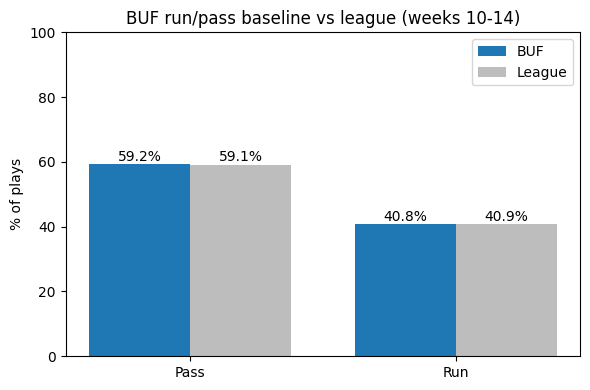

In [45]:
# League over the same weeks, so both bars describe the same stretch of the season
league_pass_pct = pbp_2025[pbp_2025["week"].between(first, last)]["qb_dropback"].mean() * 100
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2); w = 0.38
ax.bar(x - w / 2, [team_pass_pct, 100 - team_pass_pct], w, label=team, color="#1f77b4")
ax.bar(x + w / 2, [league_pass_pct, 100 - league_pass_pct], w, label="League", color="#bdbdbd")
for i, (a, b) in enumerate(zip([team_pass_pct, 100 - team_pass_pct], [league_pass_pct, 100 - league_pass_pct])):
    ax.text(i - w / 2, a + 1, f"{a:.1f}%", ha="center"); ax.text(i + w / 2, b + 1, f"{b:.1f}%", ha="center")
ax.set_xticks(x); ax.set_xticklabels(["Pass", "Run"]); ax.set_ylim(0, 100)
ax.set_ylabel("% of plays"); ax.set_title(f"{team} run/pass baseline vs league (weeks {TRAIN_LABEL})"); ax.legend()
plt.tight_layout(); plt.show()

### Step 3: Baseline - run/pass % by down & distance

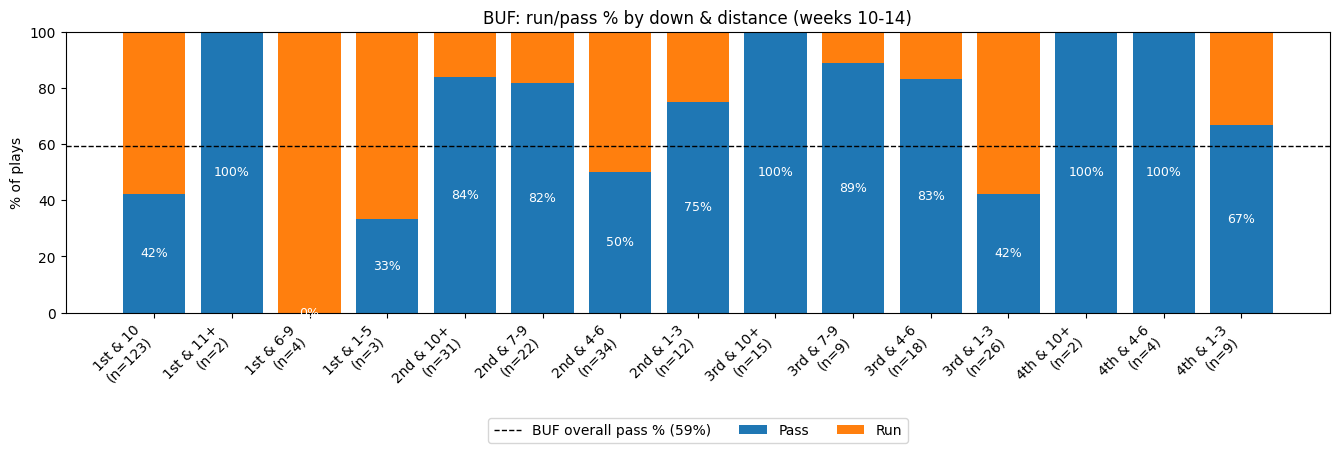

In [46]:
plot_pass_run_by_group("dd_bucket", DD_ORDER, f"{team}: run/pass % by down & distance")

### Step 4: Baseline - run/pass % by personnel (`n_rb` incl. FB, `n_te`, `n_wr`, 6 OL tagged)

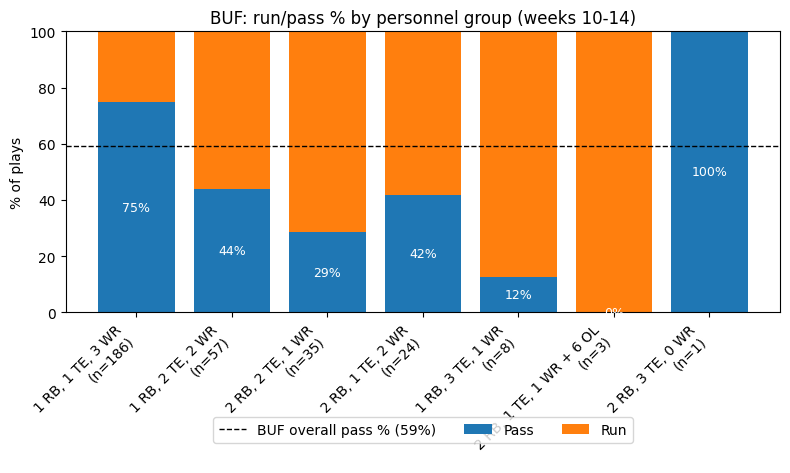

In [47]:
plot_pass_run_by_group("personnel", PERS_ORDER, f"{team}: run/pass % by personnel group")

### Step 5: Baseline - run/pass % by down & distance + personnel

Heatmap of pass % (cell text = pass %, n). Gray cells have no plays.

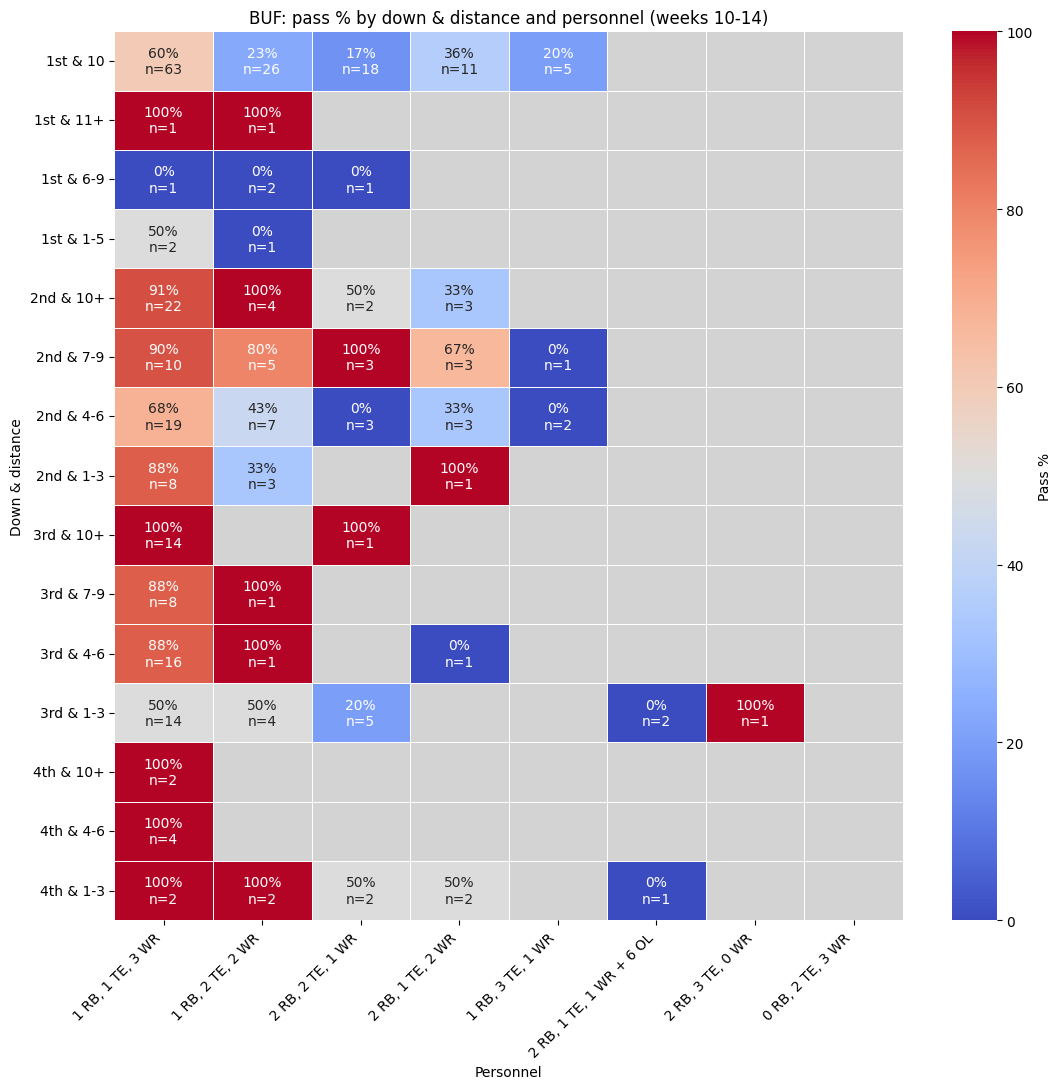

In [48]:
# Training weeks only, so the heatmap describes what a coach could scout
pct = train.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="mean") * 100
cnt = train.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="count")
rows = [r for r in DD_ORDER if r in pct.index]
pct, cnt = pct.reindex(index=rows, columns=PERS_ORDER), cnt.reindex(index=rows, columns=PERS_ORDER)
annot = pct.copy().astype(object)
for r in pct.index:
    for c in pct.columns:
        annot.loc[r, c] = "" if np.isnan(pct.loc[r, c]) else f"{pct.loc[r, c]:.0f}%\nn={int(cnt.loc[r, c])}"
fig, ax = plt.subplots(figsize=(max(8, 1.4 * len(PERS_ORDER)), 0.6 * len(rows) + 2))
ax.set_facecolor("lightgray")
sns.heatmap(pct, annot=annot, fmt="", cmap="coolwarm", center=50, vmin=0, vmax=100,
            cbar_kws={"label": "Pass %"}, linewidths=0.5, ax=ax)
ax.set_xlabel("Personnel"); ax.set_ylabel("Down & distance")
ax.set_title(f"{team}: pass % by down & distance and personnel (weeks {TRAIN_LABEL})")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

### Step 5b: Baseline - run/pass % by down & distance + personnel (stacked bars)

One chart per down. Each bar is a down & distance bucket + personnel group, shaded by bucket, with the pass % (blue) and run % (orange) and the play count `n`.
`MIN_PLAYS` hides very rare combinations so the bars stay readable (set it to 1 to show every combination).

Showing combos with n >= 5; hiding 32 combos (63 of 314 plays).


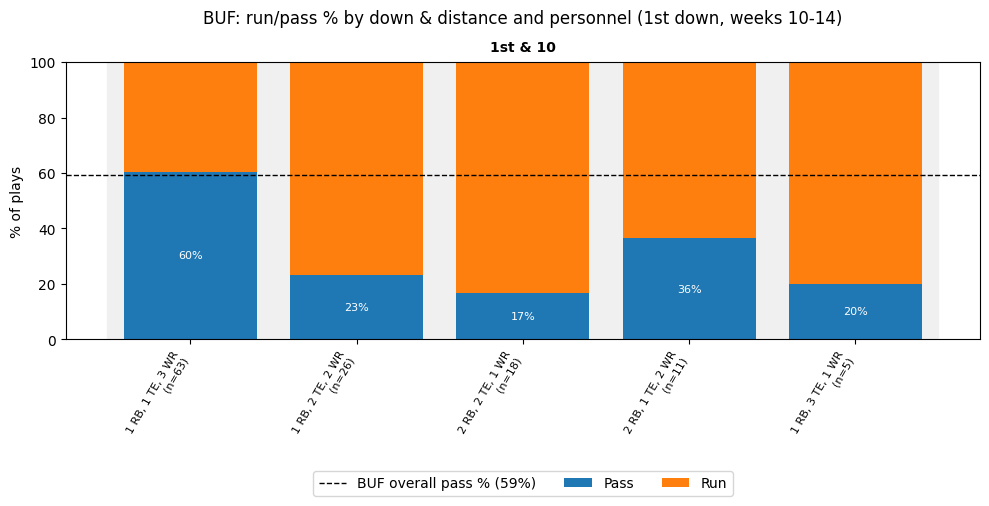

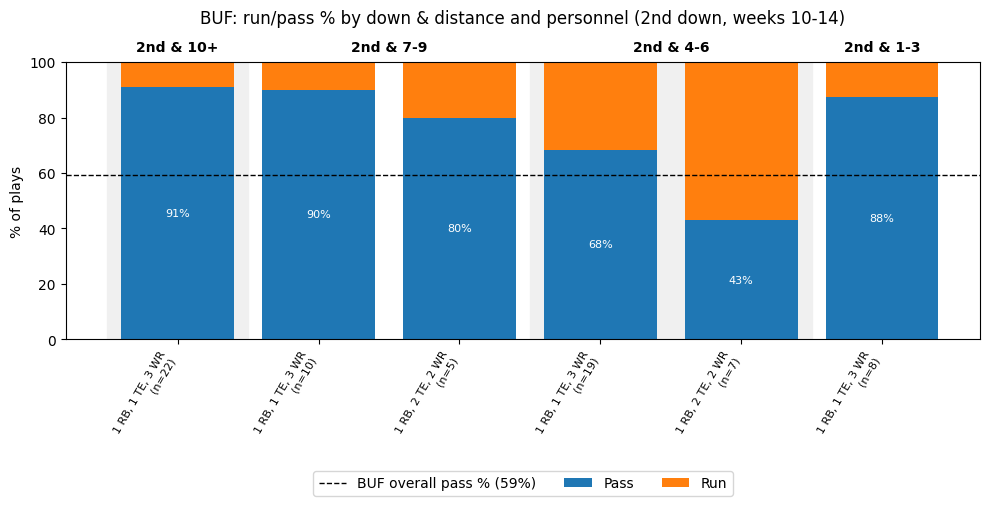

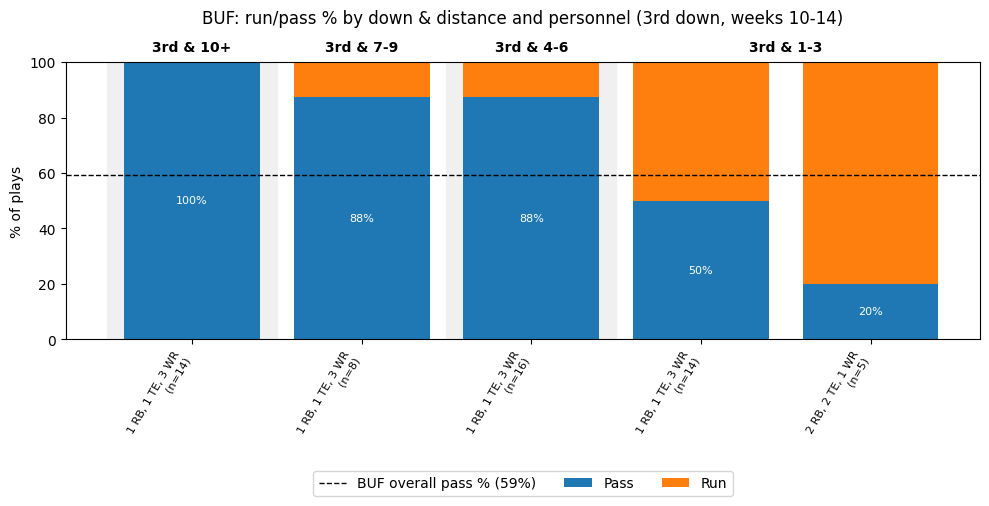

4th down: no combinations with n >= 5


In [49]:
MIN_PLAYS = 5   # hide down & distance + personnel combos with fewer plays than this (1 = show all)

# Training weeks only, so the bars describe what a coach could scout
combo = (train.groupby(["dd_bucket", "personnel"])["pass_play"]
         .agg(pass_pct="mean", n="count").reset_index())
combo["pass_pct"] *= 100
hidden = combo[combo["n"] < MIN_PLAYS]
print(f"Showing combos with n >= {MIN_PLAYS}; hiding {len(hidden)} combos "
      f"({int(hidden['n'].sum())} of {len(train)} plays).")

for down_name in ["1st", "2nd", "3rd", "4th"]:
    buckets = [b for b in DD_ORDER if b.startswith(down_name)]
    d = combo[combo["dd_bucket"].isin(buckets) & (combo["n"] >= MIN_PLAYS)].copy()
    if d.empty:
        print(f"{down_name} down: no combinations with n >= {MIN_PLAYS}"); continue
    # order: down & distance bucket first, then the most common personnel within it
    d["b_order"] = d["dd_bucket"].map({b: i for i, b in enumerate(DD_ORDER)})
    d = d.sort_values(["b_order", "n"], ascending=[True, False]).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(max(10, 0.6 * len(d)), 6))
    x = np.arange(len(d))
    ax.bar(x, d["pass_pct"], color="#1f77b4", label="Pass")
    ax.bar(x, 100 - d["pass_pct"], bottom=d["pass_pct"], color="#ff7f0e", label="Run")
    for i, p in enumerate(d["pass_pct"]):
        ax.text(i, p / 2, f"{p:.0f}%", ha="center", va="center", color="white", fontsize=8)
    ax.axhline(team_pass_pct, color="black", linestyle="--", linewidth=1,
               label=f"{team} overall pass % ({team_pass_pct:.0f}%)")

    # shade each down & distance bucket and label it above the bars
    for k, b in enumerate(buckets):
        idx = d.index[d["dd_bucket"] == b]
        if len(idx) == 0: continue
        lo, hi = idx.min() - 0.5, idx.max() + 0.5
        if k % 2 == 0: ax.axvspan(lo, hi, color="#f0f0f0", zorder=0)
        ax.text((lo + hi) / 2, 103, b, ha="center", va="bottom", fontsize=10, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels([f"{p}\n(n={n})" for p, n in zip(d["personnel"], d["n"])], rotation=60, ha="right", fontsize=8)
    ax.set_ylim(0, 100); ax.set_ylabel("% of plays")
    ax.set_title(f"{team}: run/pass % by down & distance and personnel ({down_name} down, weeks {TRAIN_LABEL})", pad=28)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3)
    plt.tight_layout(); plt.show()

## Logistic Regression (steps 6-9)

### LR.6 Logistic Regression: overall run/pass prediction

Features: all pre-snap features in `FEATURES`. Baseline: always guess the team's majority play. Benchmark: nflfastR's `xpass`. Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Logistic Regression | step 6 | best settings: {'logisticregression__C': 0.1} (CV accuracy 0.713)


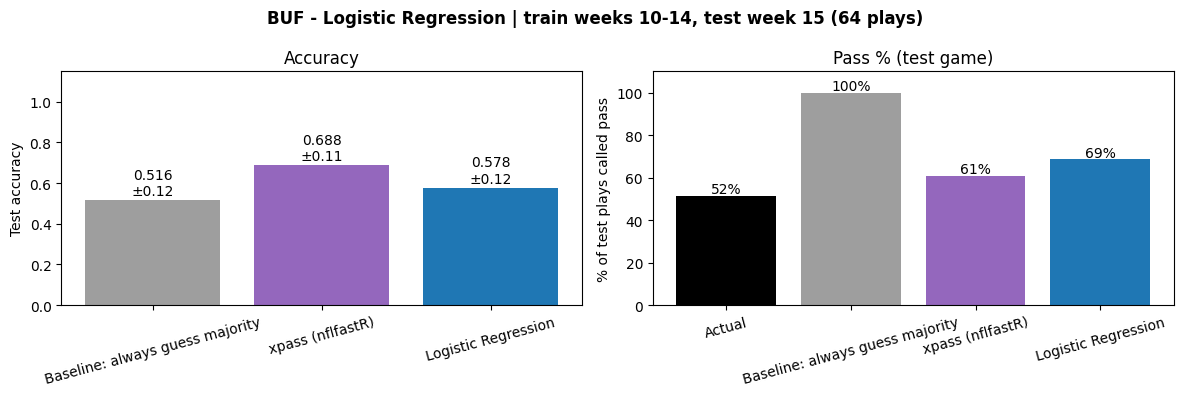

In [50]:
pred, base = run_model("Logistic Regression", FEATURES, [], step=6)
plot_overall("Logistic Regression", pred, base, "Baseline: always guess majority")

### LR.7 Logistic Regression: down & distance

Features: `down`, `ydstogo` only. Baseline: majority play of each down & distance bucket (step 3). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Logistic Regression | step 7 | best settings: {'logisticregression__C': 0.01} (CV accuracy 0.607)


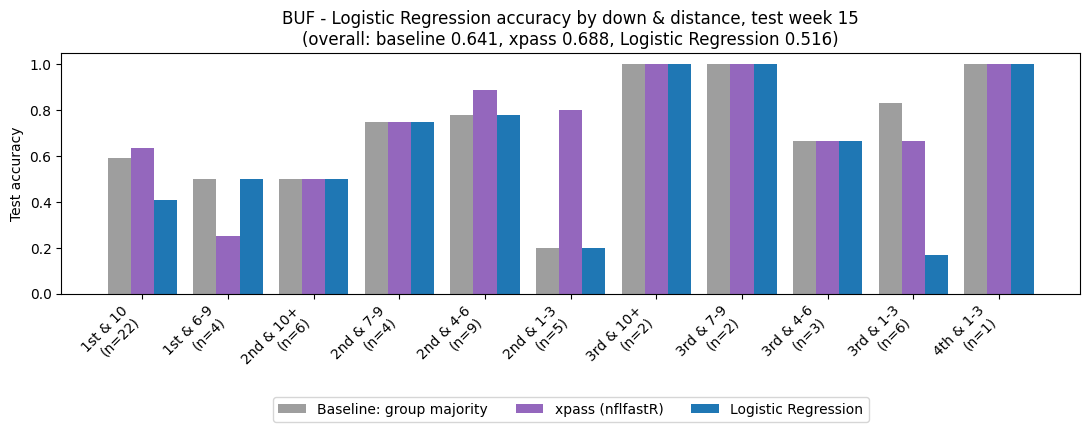

In [51]:
pred, base = run_model("Logistic Regression", ["down", "ydstogo"], ["dd_bucket"], step=7)
plot_group_accuracy("Logistic Regression", pred, base, "dd_bucket", DD_ORDER,
                    "Logistic Regression accuracy by down & distance", "Baseline: group majority")

### LR.8 Logistic Regression: personnel

Features: `n_te`, `n_wr`, `n_ol` only (RB is the reference position). Baseline: majority play of each personnel group (step 4). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Logistic Regression | step 8 | best settings: {'logisticregression__C': 0.1} (CV accuracy 0.661)


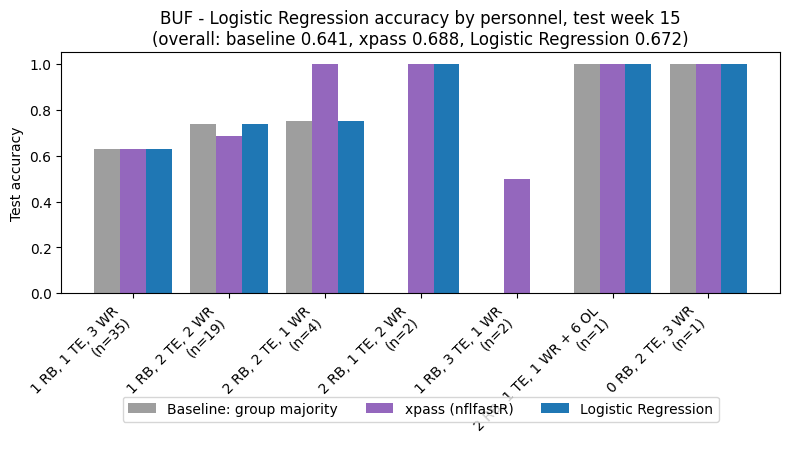

In [52]:
pred, base = run_model("Logistic Regression", ["n_te", "n_wr", "n_ol"], ["personnel"], step=8)
plot_group_accuracy("Logistic Regression", pred, base, "personnel", PERS_ORDER,
                    "Logistic Regression accuracy by personnel", "Baseline: group majority")

### LR.9 Logistic Regression: down & distance + personnel

Features: `down`, `ydstogo`, `n_te`, `n_wr`, `n_ol`. Baseline: majority play of each down & distance + personnel combo (step 5). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Logistic Regression | step 9 | best settings: {'logisticregression__C': 1} (CV accuracy 0.734)


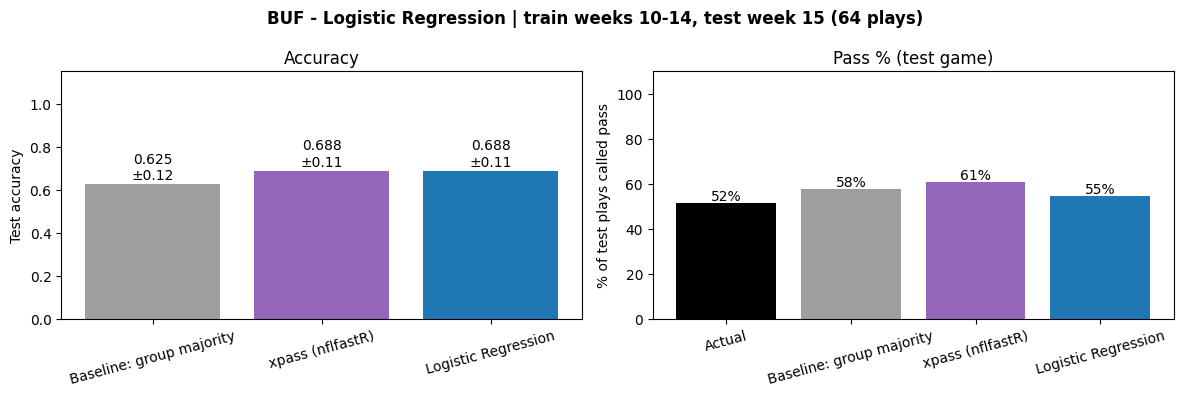

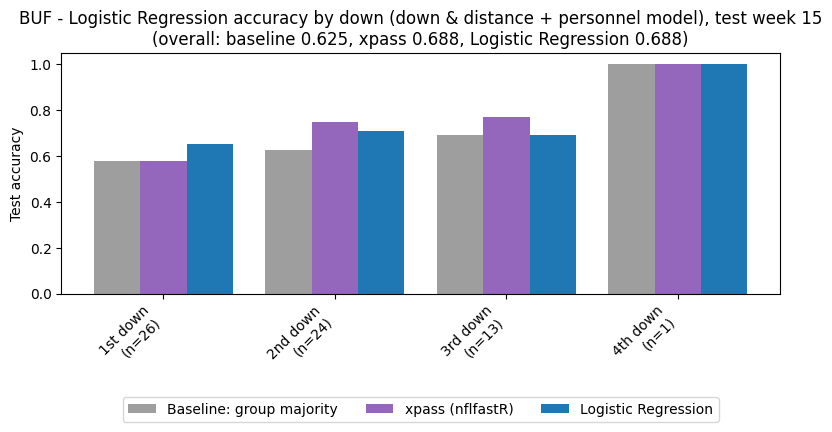

In [53]:
pred, base = run_model("Logistic Regression", ["down", "ydstogo", "n_te", "n_wr", "n_ol"], ["dd_bucket", "personnel"], step=9)
plot_overall("Logistic Regression", pred, base, "Baseline: group majority")
plot_group_accuracy("Logistic Regression", pred, base, "down_label", DOWN_ORDER,
                    "Logistic Regression accuracy by down (down & distance + personnel model)", "Baseline: group majority")

### LR.F Logistic Regression: most important features

Uses the full-feature model from step 6.

The table under the chart converts the personnel coefficients to **per-player** odds ratios, read as swaps. With 11 players on the field, adding a player always means removing one, so a personnel effect only makes sense as "swap X for Y."

- Normally RB is the reference: "swap one RB for one TE: odds ratio 1.5" means that swap makes a pass 1.5 times as likely (odds), everything else held fixed.
- Many teams almost never change their RB count in a few weeks (the Rams used exactly 1 RB on every play in weeks 1-3). Then TE and WR only trade with each other, the two coefficients come out equal and opposite, and neither one means anything alone. The code detects this and reports the swap the team actually made (WR for TE) instead.

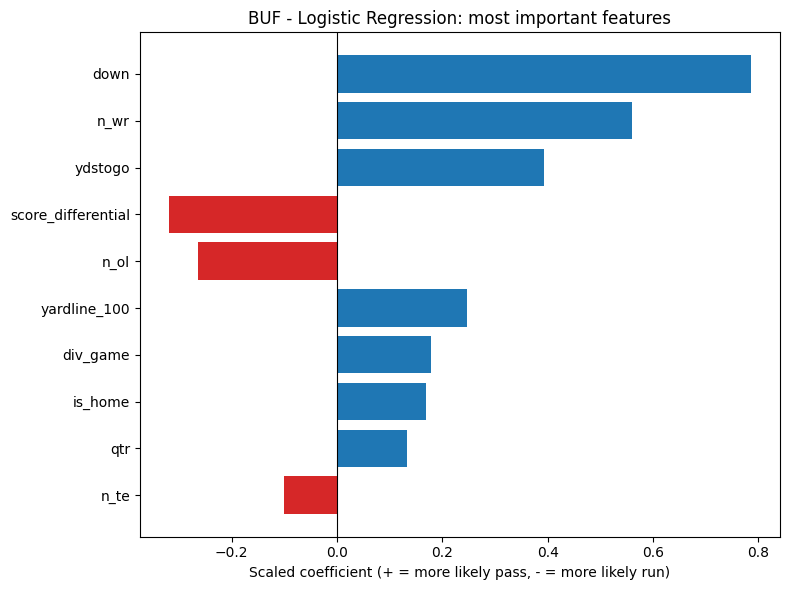

down                  0.786
n_wr                  0.560
ydstogo               0.394
score_differential   -0.319
n_ol                 -0.265
yardline_100          0.247
div_game              0.178
is_home               0.168
qtr                   0.133
n_te                 -0.101

Personnel effects (odds ratio > 1 = more likely pass; other features held fixed):
                        log-odds per player  odds ratio
swap one RB for one TE               -0.188       0.828
swap one RB for one WR                0.749       2.115
swap one RB for one OL               -2.719       0.066


In [54]:
plot_feature_importance("Logistic Regression", step=6)

## Decision Tree (step 10, repeating 6-9)

### DT.6 Decision Tree: overall run/pass prediction

Features: all pre-snap features in `FEATURES`. Baseline: always guess the team's majority play. Benchmark: nflfastR's `xpass`. Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Decision Tree | step 6 | best settings: {'max_depth': 4, 'min_samples_leaf': 20} (CV accuracy 0.708)


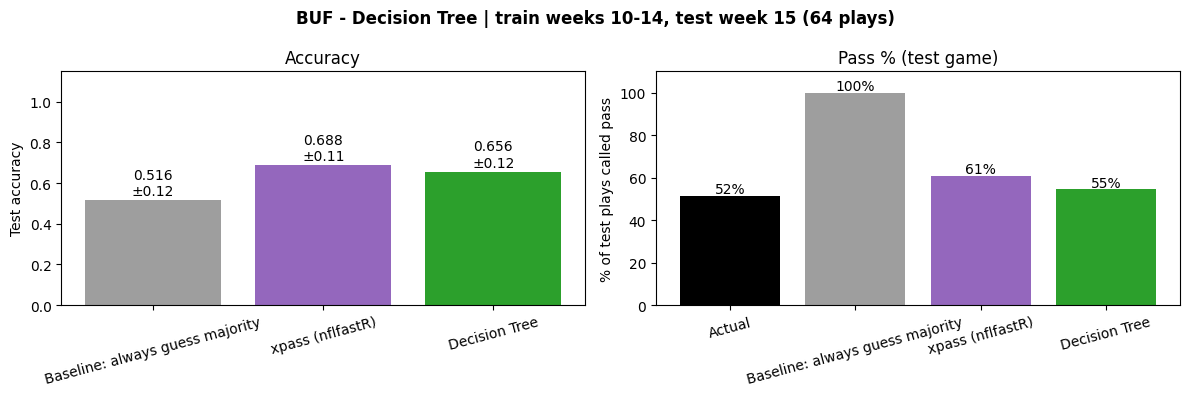

In [55]:
pred, base = run_model("Decision Tree", FEATURES, [], step=6)
plot_overall("Decision Tree", pred, base, "Baseline: always guess majority")

### DT.7 Decision Tree: down & distance

Features: `down`, `ydstogo` only. Baseline: majority play of each down & distance bucket (step 3). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Decision Tree | step 7 | best settings: {'max_depth': 2, 'min_samples_leaf': 40} (CV accuracy 0.662)


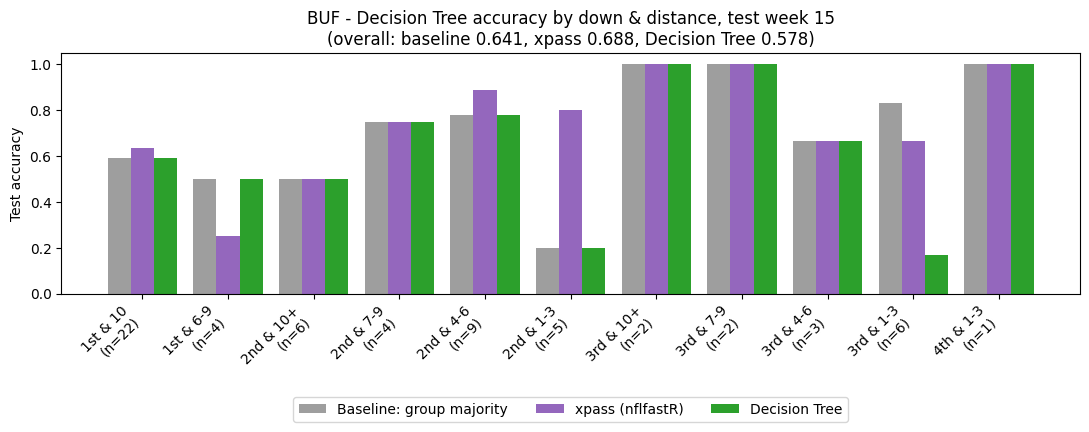

In [56]:
pred, base = run_model("Decision Tree", ["down", "ydstogo"], ["dd_bucket"], step=7)
plot_group_accuracy("Decision Tree", pred, base, "dd_bucket", DD_ORDER,
                    "Decision Tree accuracy by down & distance", "Baseline: group majority")

### DT.8 Decision Tree: personnel

Features: `n_te`, `n_wr`, `n_ol` only (RB is the reference position). Baseline: majority play of each personnel group (step 4). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Decision Tree | step 8 | best settings: {'max_depth': 2, 'min_samples_leaf': 10} (CV accuracy 0.701)


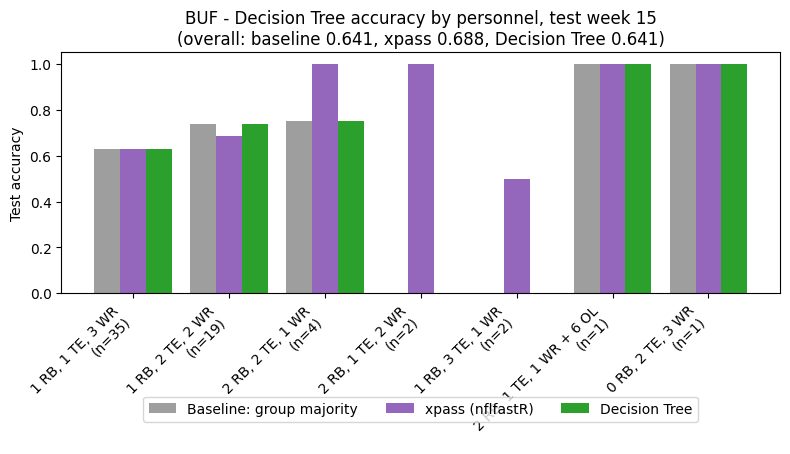

In [57]:
pred, base = run_model("Decision Tree", ["n_te", "n_wr", "n_ol"], ["personnel"], step=8)
plot_group_accuracy("Decision Tree", pred, base, "personnel", PERS_ORDER,
                    "Decision Tree accuracy by personnel", "Baseline: group majority")

### DT.9 Decision Tree: down & distance + personnel

Features: `down`, `ydstogo`, `n_te`, `n_wr`, `n_ol`. Baseline: majority play of each down & distance + personnel combo (step 5). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

Decision Tree | step 9 | best settings: {'max_depth': 3, 'min_samples_leaf': 10} (CV accuracy 0.675)


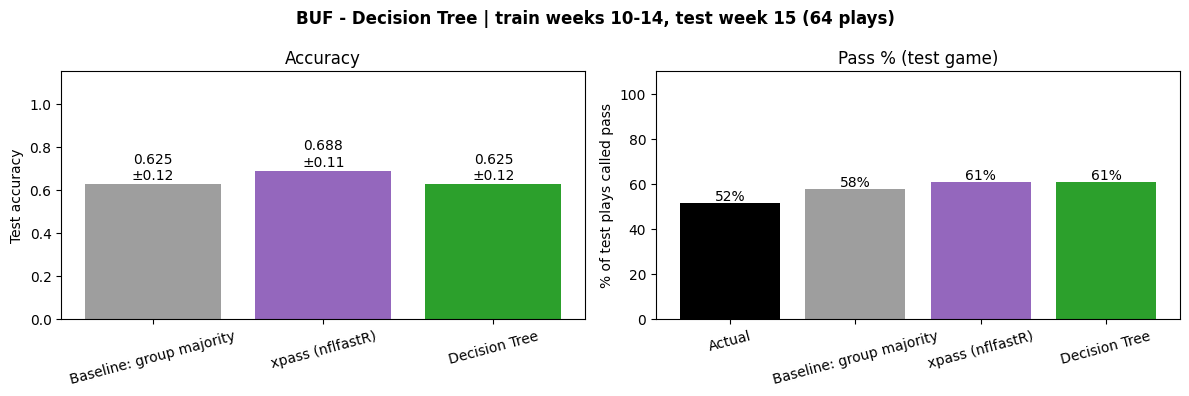

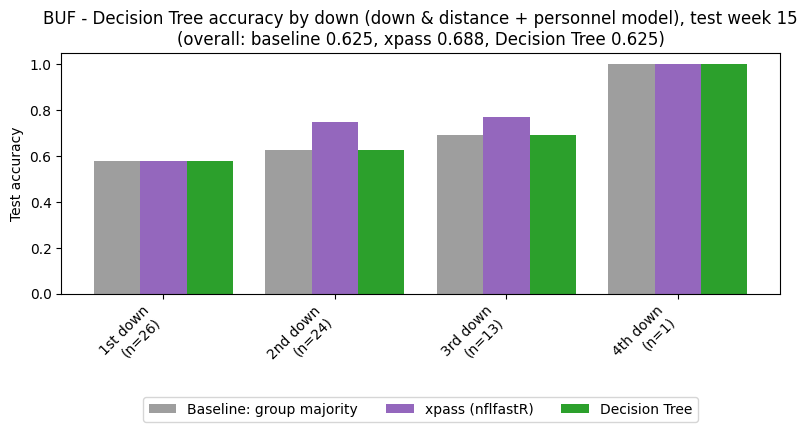

In [58]:
pred, base = run_model("Decision Tree", ["down", "ydstogo", "n_te", "n_wr", "n_ol"], ["dd_bucket", "personnel"], step=9)
plot_overall("Decision Tree", pred, base, "Baseline: group majority")
plot_group_accuracy("Decision Tree", pred, base, "down_label", DOWN_ORDER,
                    "Decision Tree accuracy by down (down & distance + personnel model)", "Baseline: group majority")

### DT.F Decision Tree: most important features

Uses the full-feature model from step 6.

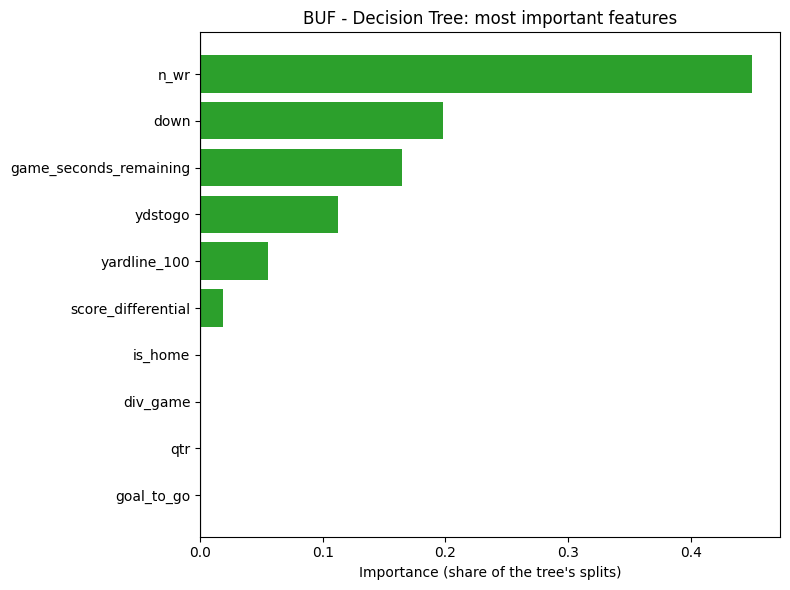

n_wr                      0.450
down                      0.198
game_seconds_remaining    0.165
ydstogo                   0.113
yardline_100              0.056
score_differential        0.019
is_home                   0.000
div_game                  0.000
qtr                       0.000
goal_to_go                0.000


In [59]:
plot_feature_importance("Decision Tree", step=6)

## KNN (step 10, repeating 6-9)

### KNN.6 KNN: overall run/pass prediction

Features: all pre-snap features in `FEATURES`. Baseline: always guess the team's majority play. Benchmark: nflfastR's `xpass`. Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

KNN | step 6 | best settings: {'kneighborsclassifier__n_neighbors': 15} (CV accuracy 0.677)


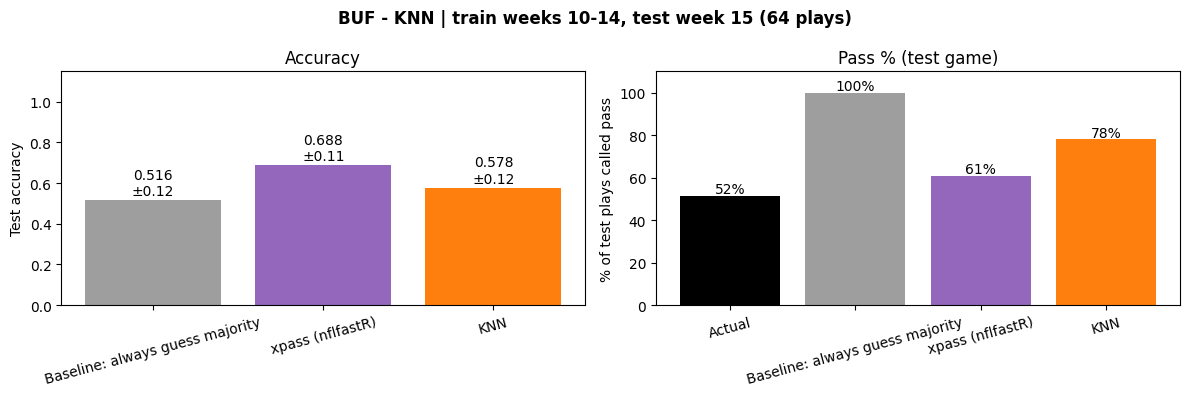

In [60]:
pred, base = run_model("KNN", FEATURES, [], step=6)
plot_overall("KNN", pred, base, "Baseline: always guess majority")

### KNN.7 KNN: down & distance

Features: `down`, `ydstogo` only. Baseline: majority play of each down & distance bucket (step 3). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

KNN | step 7 | best settings: {'kneighborsclassifier__n_neighbors': 11} (CV accuracy 0.665)


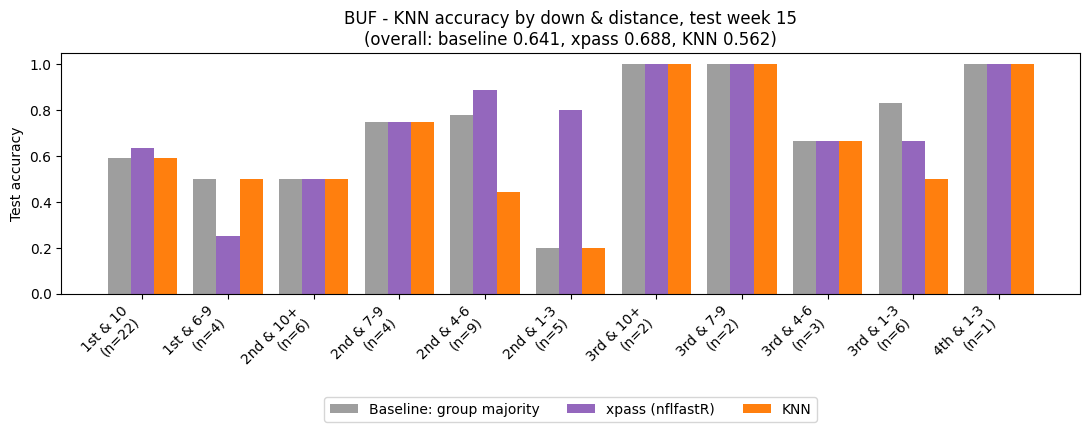

In [61]:
pred, base = run_model("KNN", ["down", "ydstogo"], ["dd_bucket"], step=7)
plot_group_accuracy("KNN", pred, base, "dd_bucket", DD_ORDER,
                    "KNN accuracy by down & distance", "Baseline: group majority")

### KNN.8 KNN: personnel

Features: `n_te`, `n_wr`, `n_ol` only (RB is the reference position). Baseline: majority play of each personnel group (step 4). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

KNN | step 8 | best settings: {'kneighborsclassifier__n_neighbors': 45} (CV accuracy 0.685)


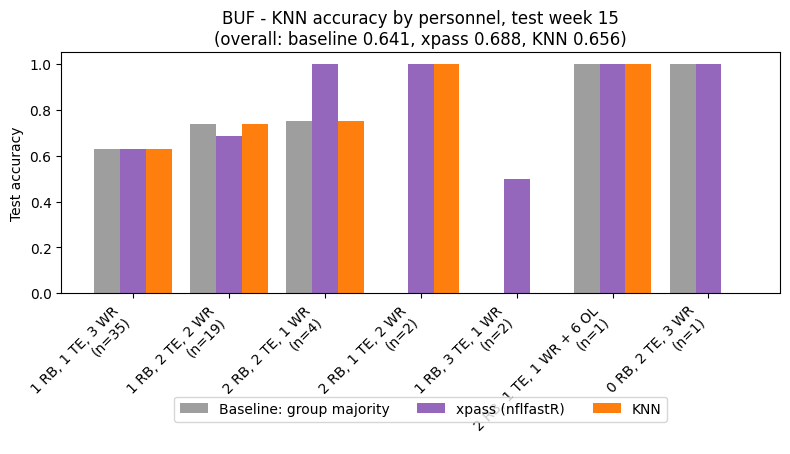

In [62]:
pred, base = run_model("KNN", ["n_te", "n_wr", "n_ol"], ["personnel"], step=8)
plot_group_accuracy("KNN", pred, base, "personnel", PERS_ORDER,
                    "KNN accuracy by personnel", "Baseline: group majority")

### KNN.9 KNN: down & distance + personnel

Features: `down`, `ydstogo`, `n_te`, `n_wr`, `n_ol`. Baseline: majority play of each down & distance + personnel combo (step 5). Settings tuned with GridSearchCV (set `USE_GRIDSEARCH = False` in the helpers cell to turn off).

KNN | step 9 | best settings: {'kneighborsclassifier__n_neighbors': 5} (CV accuracy 0.689)


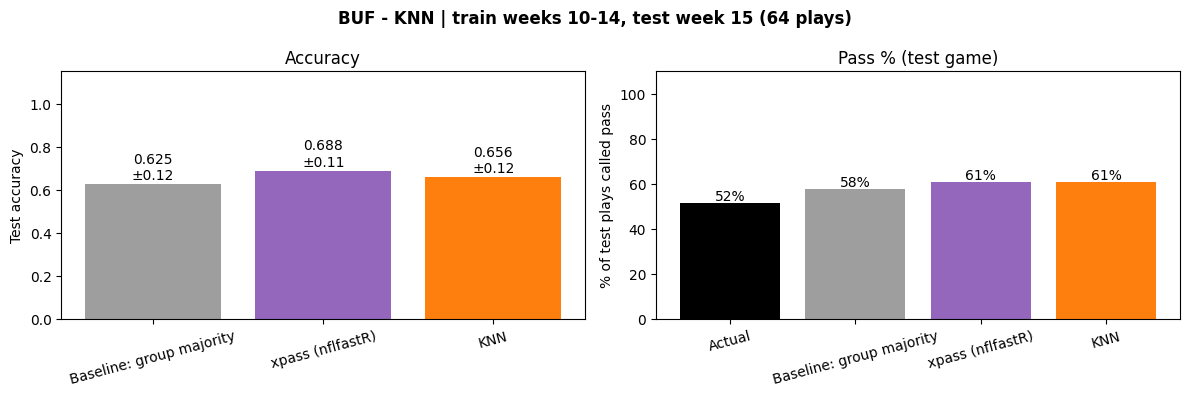

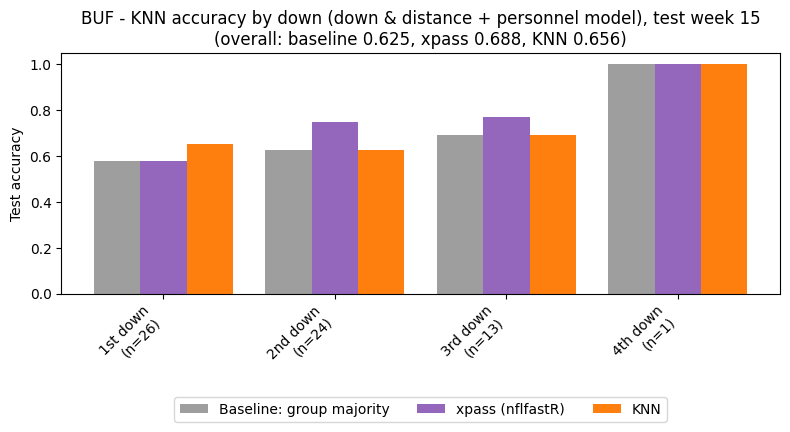

In [63]:
pred, base = run_model("KNN", ["down", "ydstogo", "n_te", "n_wr", "n_ol"], ["dd_bucket", "personnel"], step=9)
plot_overall("KNN", pred, base, "Baseline: group majority")
plot_group_accuracy("KNN", pred, base, "down_label", DOWN_ORDER,
                    "KNN accuracy by down (down & distance + personnel model)", "Baseline: group majority")

### KNN.F KNN: most important features

Uses the full-feature model from step 6.

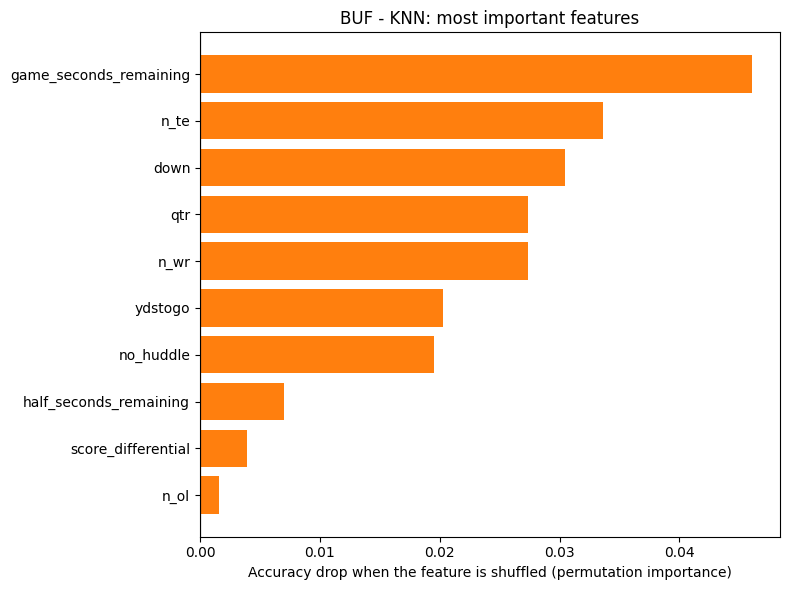

game_seconds_remaining    0.046
n_te                      0.034
down                      0.030
qtr                       0.027
n_wr                      0.027
ydstogo                   0.020
no_huddle                 0.020
half_seconds_remaining    0.007
score_differential        0.004
n_ol                      0.002


In [64]:
plot_feature_importance("KNN", step=6)

### Summary: test accuracy by step and model

Train weeks 10-14, test week 15, 64 test plays (95% margin of error about ±0.11)
                 Baseline  xpass  Logistic Regression  Decision Tree    KNN
Step                                                                       
Overall             0.516  0.688                0.578          0.656  0.578
Down & distance     0.641  0.688                0.516          0.578  0.562
Personnel           0.641  0.688                0.672          0.641  0.656
D&D + personnel     0.625  0.688                0.688          0.625  0.656


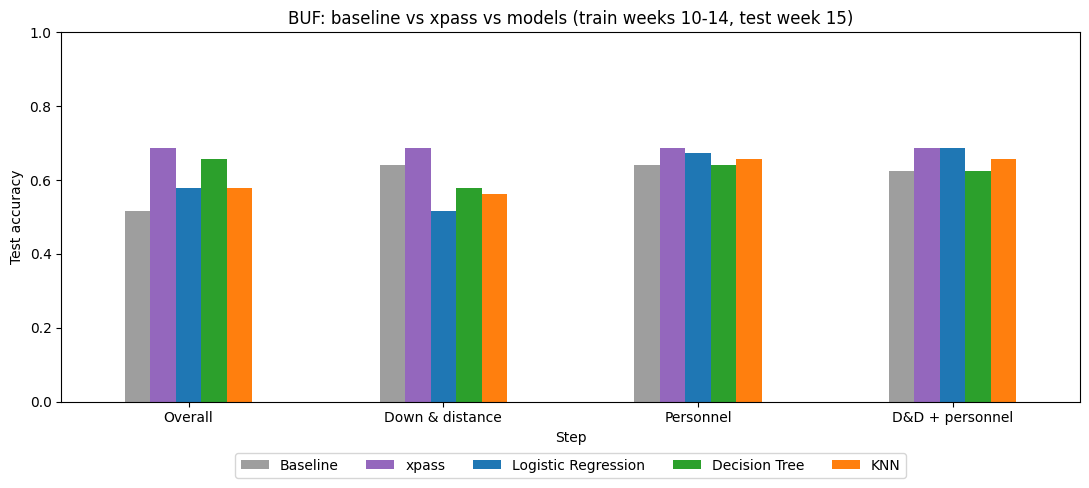


Settings chosen by GridSearchCV:
  Logistic Regression | step 6: {'logisticregression__C': 0.1}
  Logistic Regression | step 7: {'logisticregression__C': 0.01}
  Logistic Regression | step 8: {'logisticregression__C': 0.1}
  Logistic Regression | step 9: {'logisticregression__C': 1}
  Decision Tree | step 6: {'max_depth': 4, 'min_samples_leaf': 20}
  Decision Tree | step 7: {'max_depth': 2, 'min_samples_leaf': 40}
  Decision Tree | step 8: {'max_depth': 2, 'min_samples_leaf': 10}
  Decision Tree | step 9: {'max_depth': 3, 'min_samples_leaf': 10}
  KNN | step 6: {'kneighborsclassifier__n_neighbors': 15}
  KNN | step 7: {'kneighborsclassifier__n_neighbors': 11}
  KNN | step 8: {'kneighborsclassifier__n_neighbors': 45}
  KNN | step 9: {'kneighborsclassifier__n_neighbors': 5}


In [65]:
step_names = {6: "Overall", 7: "Down & distance", 8: "Personnel", 9: "D&D + personnel"}
xpass_acc = (xpass_predictions() == test["pass_play"]).mean()   # same test plays for every step
rows = []
for step, name in step_names.items():
    row = {"Step": name, "Baseline": RESULTS[("Logistic Regression", step)][0], "xpass": xpass_acc}
    for m in ["Logistic Regression", "Decision Tree", "KNN"]:
        row[m] = RESULTS[(m, step)][1]
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Step")
print(f"Train weeks {TRAIN_LABEL}, test week {TEST_WEEK}, {len(test)} test plays "
      f"(95% margin of error about \u00b1{acc_margin(0.7, len(test)):.2f})")
print(summary.round(3))

ax = summary.plot(kind="bar", figsize=(11, 5), color=[COLORS[c] for c in summary.columns], rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("Test accuracy")
ax.set_title(f"{team}: baseline vs xpass vs models (train weeks {TRAIN_LABEL}, test week {TEST_WEEK})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
plt.tight_layout(); plt.show()

# Settings GridSearchCV picked for each model and step
print("\nSettings chosen by GridSearchCV:")
for (m, st), params in BEST_PARAMS.items():
    print(f"  {m} | step {st}: {params}")

### Rolling check: repeat the test for every game

One test game is about 60 plays, so a single result can swing by ±0.11 by luck. This cell repeats the same idea for every game the team played: train on the previous N games (N = the number of games in your range), test on the next one, and average. It uses the default settings (no GridSearchCV) so it runs quickly. If a model beats xpass here, the edge is more believable than a one-game win.

BUF: 14 test games, 881 plays, training window = 5 games
Baseline               0.554
xpass                  0.728
Logistic Regression    0.672
Decision Tree          0.671
KNN                    0.665


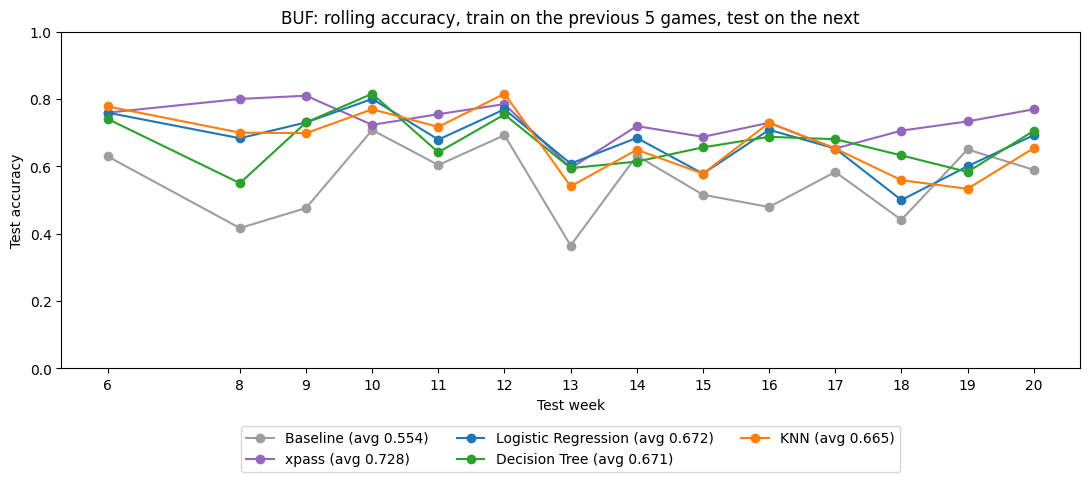

In [66]:
WINDOW = len(train_weeks)   # same training length the user picked
rows = []
for i in range(WINDOW, len(team_weeks)):
    tr_weeks, te_week = team_weeks[i - WINDOW:i], team_weeks[i]       # previous N games -> next game
    tr = team_df[team_df["week"].isin(tr_weeks)]
    te = team_df[team_df["week"] == te_week]
    y = te["pass_play"]
    majority = int(tr["pass_play"].mean() >= 0.5)                     # baseline guess from those games
    xp = (te["xpass"] >= 0.5).astype(int).where(te["xpass"].notna(), majority)
    row = {"test week": te_week, "plays": len(te), "Baseline": (y == majority).mean(), "xpass": (xp == y).mean()}
    for m in ["Logistic Regression", "Decision Tree", "KNN"]:
        fitted = make_model(m).fit(tr[FEATURES], tr["pass_play"])     # fresh model for each game
        row[m] = (fitted.predict(te[FEATURES]) == y).mean()
    rows.append(row)
roll = pd.DataFrame(rows).set_index("test week")

# Average weighted by plays, so a 75-play game counts more than a 50-play game
cols = ["Baseline", "xpass", "Logistic Regression", "Decision Tree", "KNN"]
avg = roll[cols].mul(roll["plays"], axis=0).sum() / roll["plays"].sum()
print(f"{team}: {len(roll)} test games, {int(roll['plays'].sum())} plays, training window = {WINDOW} games")
print(avg.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
for c in cols:
    ax.plot(roll.index, roll[c], marker="o", color=COLORS[c], label=f"{c} (avg {avg[c]:.3f})")
ax.set_xticks(roll.index); ax.set_ylim(0, 1)
ax.set_xlabel("Test week"); ax.set_ylabel("Test accuracy")
ax.set_title(f"{team}: rolling accuracy, train on the previous {WINDOW} games, test on the next")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout(); plt.show()